In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from sklearn.preprocessing import MinMaxScaler,StandardScaler,RobustScaler


استدعيت مكتبات ممكن احتاجهم

In [3]:
data=pd.read_csv("https://raw.githubusercontent.com/JATINKUMAR2005/Data-Preprocessing-and-Feature-Engineering-PROJECT-2-Data-Cleanser/refs/heads/main/patient_health_records_500.csv")
data

,patient_id,age,gender,region,bmi,blood_pressure,cholesterol,glucose,disease_risk
0,1001,56.0,Female,South,24.2,125.4,191.5,NaN,0
1,1002,69.0,Male,NaN,NaN,148.7,203.9,108.1,1
2,1003,46.0,Male,West,28.6,139.3,287.9,126.0,1
3,1004,32.0,Male,West,20.8,169.2,188.1,96.3,1
4,1005,60.0,Female,North,NaN,118.9,NaN,141.0,1
...,...,...,...,...,...,...,...,...,...
495,1308,76.0,Female,South,26.0,98.9,246.4,57.1,1
496,1416,21.0,Female,North,25.8,100.1,267.8,110.8,1
497,1331,53.0,Female,West,28.2,116.5,150.7,100.1,0
498,1048,64.0,Male,South,32.3,126.7,199.4,83.9,1


قرات وعرضت الداتا

In [4]:
data.shape

(500, 9)

كم صف وكم عمود فيها

In [5]:
data.head()

,patient_id,age,gender,region,bmi,blood_pressure,cholesterol,glucose,disease_risk
0,1001,56.0,Female,South,24.2,125.4,191.5,NaN,0
1,1002,69.0,Male,NaN,NaN,148.7,203.9,108.1,1
2,1003,46.0,Male,West,28.6,139.3,287.9,126.0,1
3,1004,32.0,Male,West,20.8,169.2,188.1,96.3,1
4,1005,60.0,Female,North,NaN,118.9,NaN,141.0,1


عرض اول 5 صفوف

In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   patient_id      500 non-null    int64  
 1   age             476 non-null    float64
 2   gender          475 non-null    object 
 3   region          476 non-null    object 
 4   bmi             475 non-null    float64
 5   blood_pressure  500 non-null    float64
 6   cholesterol     475 non-null    float64
 7   glucose         476 non-null    float64
 8   disease_risk    500 non-null    int64  
dtypes: float64(5), int64(2), object(2)
memory usage: 35.3+ KB


In [7]:
data.describe()

,patient_id,age,bmi,blood_pressure,cholesterol,glucose,disease_risk
count,500.000000,476.000000,475.000000,500.000000,475.000000,476.000000,500.000000
mean,1241.028000,49.758403,26.573908,125.269097,203.408309,101.329202,0.462000
std,138.397308,18.252799,4.948111,17.758512,43.028031,20.711447,0.499053
min,1001.000000,18.000000,11.700000,74.200000,101.800000,42.000000,0.000000
25%,1121.750000,34.750000,23.750000,114.200000,177.000000,88.375000,0.000000
50%,1242.500000,50.000000,26.300000,125.400000,199.700000,102.300000,0.000000
75%,1361.250000,66.000000,29.350000,136.225000,227.700000,114.000000,1.000000
max,1480.000000,79.000000,59.965084,217.226890,447.560192,165.200000,1.000000


وصف احصائي للداتا

In [8]:
cat=data.describe(include="object")
cat

,gender,region
count,475,476
unique,2,4
top,Female,South
freq,240,131


عدد القيم الغير مفقوده وعدد القيم المختلف واكثر قيمه تكررت وعدد مرات تكرار القيمه الاكثر شيوعا

In [9]:
for col in cat.columns:
    print("="*12,col,"="*12)
    print(data[col].value_counts())

============ gender ============
gender
Female    240
Male      235
Name: count, dtype: int64
============ region ============
region
South    131
North    124
East     117
West     104
Name: count, dtype: int64


In [10]:
data.isnull().sum()

,0
patient_id,0
age,24
gender,25
region,24
bmi,25
blood_pressure,0
cholesterol,25
glucose,24
disease_risk,0


بشوف كم قيمه مفقوده بكل عمود

6 أعمدة فيها Missing Values

In [11]:
data.duplicated().sum()

np.int64(20)

هون بعرف انه عندي 20 صف مكرر

In [12]:
data[data.duplicated(keep=False)]

,patient_id,age,gender,region,bmi,blood_pressure,cholesterol,glucose,disease_risk
31,1032,29.0,Male,North,24.3,114.3,225.7,103.0,0
34,1035,78.0,Male,East,24.4,150.8,151.0,112.1,1
47,1048,64.0,Male,South,32.3,126.7,199.4,83.9,1
66,1067,67.0,Female,East,28.2,150.7,191.0,113.5,1
159,1160,50.0,Female,West,27.3,111.6,NaN,103.8,0
168,1169,57.0,Female,South,21.8,144.9,208.5,84.8,1
186,1187,32.0,Female,South,28.8,132.5,179.2,98.2,0
204,1205,62.0,Female,West,25.8,140.6,185.8,83.1,1
250,1251,44.0,Female,East,30.1,106.4,168.6,86.9,1
283,1284,66.0,Female,East,22.5,139.0,179.3,64.0,0


بتساعدني اعرض جميع الصفوف المكرره

In [13]:
data_clean = data.copy()
data_clean

,patient_id,age,gender,region,bmi,blood_pressure,cholesterol,glucose,disease_risk
0,1001,56.0,Female,South,24.2,125.4,191.5,NaN,0
1,1002,69.0,Male,NaN,NaN,148.7,203.9,108.1,1
2,1003,46.0,Male,West,28.6,139.3,287.9,126.0,1
3,1004,32.0,Male,West,20.8,169.2,188.1,96.3,1
4,1005,60.0,Female,North,NaN,118.9,NaN,141.0,1
...,...,...,...,...,...,...,...,...,...
495,1308,76.0,Female,South,26.0,98.9,246.4,57.1,1
496,1416,21.0,Female,North,25.8,100.1,267.8,110.8,1
497,1331,53.0,Female,West,28.2,116.5,150.7,100.1,0
498,1048,64.0,Male,South,32.3,126.7,199.4,83.9,1


عملت نسخه جديده من الداتا عشان اشتغل عليها

In [14]:
data_clean = data_clean.drop_duplicates()

حذفت الصفوف المكرره بتحذف الصف المكرر وبتخلي نسخه وحده بس

In [15]:
data_clean.duplicated().sum()

np.int64(0)

هون عشان اشوف اذا  في لسا تكرار

In [16]:
data.shape

(500, 9)

In [17]:
data_clean.shape

(480, 9)

خلصت من التكرار

In [18]:
data_clean["gender"].value_counts()

,count
gender,
Female,228
Male,228


بشوف بهاد العمود كل فئه كم مره ضهرت لكنها ما بتحسب الميسنغ فاليو يعني يمكن هون في ميستغ  بس ما انحسب  

In [19]:
data_clean["region"].value_counts()

,count
region,
South,124
North,121
East,110
West,101


In [20]:
data_clean["gender"].unique()

array(['Female', 'Male', nan], dtype=object)

عرض القيم المختلفه الموجوده في العمود بدون تكلرار الها

In [21]:
data_clean["region"].unique()

array(['South', nan, 'West', 'North', 'East'], dtype=object)

In [22]:
data_clean["gender"].nunique()

2

ما بتحسب الميسنغ

In [23]:
data_clean["region"].nunique()

4

خلصنا من القيمه الفئويه وحننتقل للقيم النوميريكل وكيف اتعامل مع الميسينغ الموجود عندي  

In [26]:
data_clean["age"] = data_clean["age"].fillna(data_clean["age"].median())
data_clean["bmi"] = data_clean["bmi"].fillna(data_clean["bmi"].median())

data_clean["cholesterol"] = data_clean["cholesterol"].fillna(data_clean["cholesterol"].median())
data_clean["glucose"] = data_clean["glucose"].fillna(data_clean["glucose"].median())
data_clean["age"] = data_clean["age"].astype(int)

/tmp/ipykernel_4796/1228010152.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_clean["age"] = data_clean["age"].fillna(data_clean["age"].median())
/tmp/ipykernel_4796/1228010152.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_clean["bmi"] = data_clean["bmi"].fillna(data_clean["bmi"].median())
/tmp/ipykernel_4796/1228010152.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveat

In [27]:
data_clean["gender"] = data_clean["gender"].fillna(data_clean["gender"].mode()[0])
data_clean["region"] = data_clean["region"].fillna(data_clean["region"].mode()[0])

/tmp/ipykernel_4796/3758711718.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_clean["gender"] = data_clean["gender"].fillna(data_clean["gender"].mode()[0])
/tmp/ipykernel_4796/3758711718.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_clean["region"] = data_clean["region"].fillna(data_clean["region"].mode()[0])


In [28]:
data_clean.isnull().sum()

,0
patient_id,0
age,0
gender,0
region,0
bmi,0
blood_pressure,0
cholesterol,0
glucose,0
disease_risk,0


In [29]:
data_clean

,patient_id,age,gender,region,bmi,blood_pressure,cholesterol,glucose,disease_risk
0,1001,56,Female,South,24.2,125.4,191.50,102.55,0
1,1002,69,Male,South,26.4,148.7,203.90,108.10,1
2,1003,46,Male,West,28.6,139.3,287.90,126.00,1
3,1004,32,Male,West,20.8,169.2,188.10,96.30,1
4,1005,60,Female,North,26.4,118.9,201.05,141.00,1
...,...,...,...,...,...,...,...,...,...
475,1476,70,Female,North,24.3,121.2,242.10,111.40,1
476,1477,48,Female,North,30.5,151.9,185.80,111.20,1
477,1478,52,Female,South,24.9,126.2,151.60,112.10,0
478,1479,77,Female,West,31.5,121.7,175.40,72.30,1


In [30]:
data.sample(10)

,patient_id,age,gender,region,bmi,blood_pressure,cholesterol,glucose,disease_risk
260,1261,76.0,Male,East,15.4,131.7,112.4,148.4,1
494,1187,32.0,Female,South,28.8,132.5,179.2,98.2,0
447,1448,NaN,Male,East,31.2,137.3,217.0,108.7,1
431,1432,NaN,Male,West,NaN,98.4,162.2,117.9,0
163,1164,79.0,Male,West,26.4,136.9,180.2,NaN,0
434,1435,63.0,Male,West,29.7,112.1,202.8,90.5,0
54,1055,20.0,Female,NaN,29.5,135.6,174.9,105.8,0
491,1160,50.0,Female,West,27.3,111.6,NaN,103.8,0
256,1257,59.0,Female,West,26.7,125.9,203.7,107.4,0
85,1086,67.0,Female,South,27.1,127.9,207.3,94.5,0


In [31]:
data_clean.sample(10)

,patient_id,age,gender,region,bmi,blood_pressure,cholesterol,glucose,disease_risk
61,1062,35,Female,North,24.0,118.2,203.900000,128.30,1
307,1308,76,Female,South,26.0,98.9,246.400000,57.10,1
317,1318,65,Male,East,25.9,117.4,232.100000,158.50,1
72,1073,37,Male,North,26.4,93.2,432.183932,83.80,0
121,1122,43,Female,East,29.8,124.5,169.300000,112.70,0
439,1440,68,Female,North,29.5,121.5,235.500000,129.40,1
395,1396,37,Female,East,36.3,124.0,215.900000,90.00,1
130,1131,62,Male,East,26.4,88.8,103.400000,86.60,0
213,1214,68,Male,North,24.6,148.7,273.200000,104.80,1
163,1164,79,Male,West,26.4,136.9,180.200000,102.55,0


تنضيف النصوص

In [32]:
text_columns = data_clean.select_dtypes(include="object").columns
for col in text_columns:
    print("="*12, col, "="*12)
    print(data_clean[col].unique())

============ gender ============
['Female' 'Male']
============ region ============
['South' 'West' 'North' 'East']


In [35]:
for col in text_columns:

    print("="*12, col, "="*12)
    print(data_clean[col].str.strip().unique())

============ gender ============
['Female' 'Male']
============ region ============
['South' 'West' 'North' 'East']


In [36]:
data_clean.dtypes



,0
patient_id,int64
age,int64
gender,object
region,object
bmi,float64
blood_pressure,float64
cholesterol,float64
glucose,float64
disease_risk,int64


هون رح ابدا بالاوتلير

In [38]:
for col in ["age", "bmi", "blood_pressure", "cholesterol", "glucose"]:
    Q1 = data_clean[col].quantile(0.25)
    Q3 = data_clean[col].quantile(0.75)
    IQR = Q3 - Q1

    low = Q1 - IQR*1.5
    up = Q3 + 1.5 * IQR
    outliers = data_clean[
        (data_clean[col] < low) | (data_clean[col] > up)
    ]

    print("="*12, col, "="*12)
    print("Number of outliers:", len(outliers))

============ age ============
Number of outliers: 0
============ bmi ============
Number of outliers: 12
============ blood_pressure ============
Number of outliers: 8
============ cholesterol ============
Number of outliers: 9
============ glucose ============
Number of outliers: 13


بحسب عدد الاوتلير في الاعمده الرقميه

In [39]:
for col in ["bmi", "blood_pressure", "cholesterol", "glucose"]:
    Q1 = data_clean[col].quantile(0.25)
    Q3 = data_clean[col].quantile(0.75)
    IQR = Q3 - Q1

    low = Q1 - IQR*1.5
    up = Q3 + 1.5 * IQR

    print("="*12, col, "="*12)
    print("Lower Bound:", low)
    print("Upper Bound:", up)

============ bmi ============
Lower Bound: 15.887500000000001
Upper Bound: 37.1875
============ blood_pressure ============
Lower Bound: 81.3125
Upper Bound: 169.0125
============ cholesterol ============
Lower Bound: 107.23749999999995
Upper Bound: 299.13750000000005
============ glucose ============
Lower Bound: 54.57499999999998
Upper Bound: 148.97500000000002


كل عمود شو الابر واللوير اله

In [40]:
data_capped = data_clean.copy()

انشات نسخه للمعالجه

In [41]:
for col in ["bmi", "blood_pressure", "cholesterol", "glucose"]:

    Q1 = data_capped[col].quantile(0.25)
    Q3 = data_capped[col].quantile(0.75)

    IQR = Q3 - Q1

    low = Q1 - IQR * 1.5
    up = Q3 + 1.5 * IQR

    data_capped[col] = data_capped[col].clip(lower=low, upper=up)

اي قيمه اقل من اللوير تتحول للوير واي قيمه اكبر من الابر تتحول ل ابر

In [42]:
for col in ["bmi", "blood_pressure", "cholesterol", "glucose"]:

    Q1 = data_capped[col].quantile(0.25)
    Q3 = data_capped[col].quantile(0.75)

    IQR = Q3 - Q1

    low = Q1 - 1.5 * IQR
    up = Q3 + 1.5 * IQR

    outliers = data_capped[
        (data_capped[col] < low) | (data_capped[col] > up)
    ]

    print("="*12, col, "="*12)
    print("Number of outliers:", len(outliers))

============ bmi ============
Number of outliers: 0
============ blood_pressure ============
Number of outliers: 0
============ cholesterol ============
Number of outliers: 0
============ glucose ============
Number of outliers: 0


برجع احسب عدد الاوتلير بعد المعالجه

In [43]:
print("Original Data:", data.shape)
print("Clean Data:", data_clean.shape)
print("Capped Data:", data_capped.shape)

Original Data: (500, 9)
Clean Data: (480, 9)
Capped Data: (480, 9)


برجع اعمل مقارنه

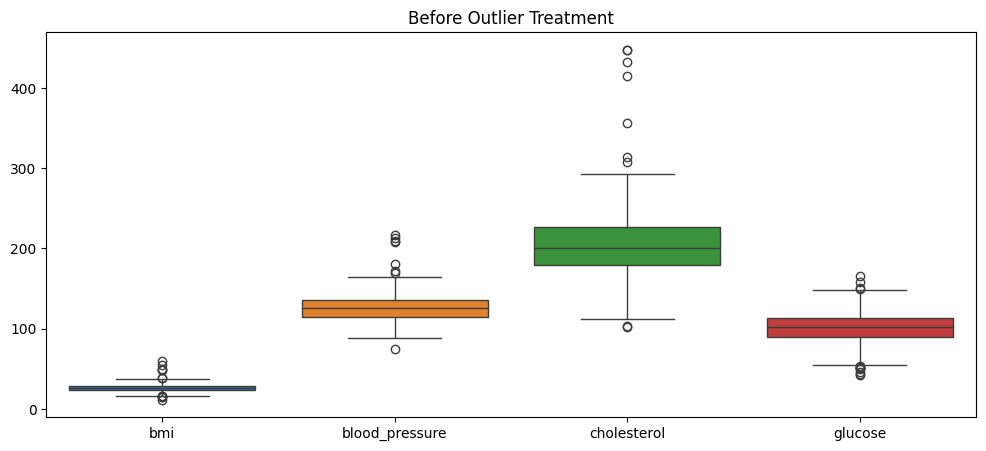

In [44]:
plt.figure(figsize=(12, 5))

sns.boxplot(data=data_clean[["bmi", "blood_pressure", "cholesterol", "glucose"]])

plt.title("Before Outlier Treatment")
plt.show()

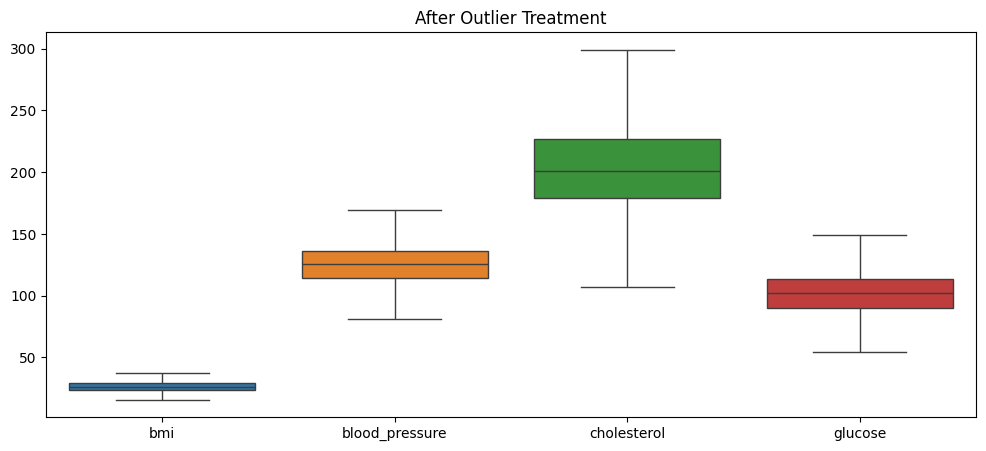

In [45]:
plt.figure(figsize=(12, 5))

sns.boxplot(data=data_capped[["bmi", "blood_pressure", "cholesterol", "glucose"]])

plt.title("After Outlier Treatment")
plt.show()

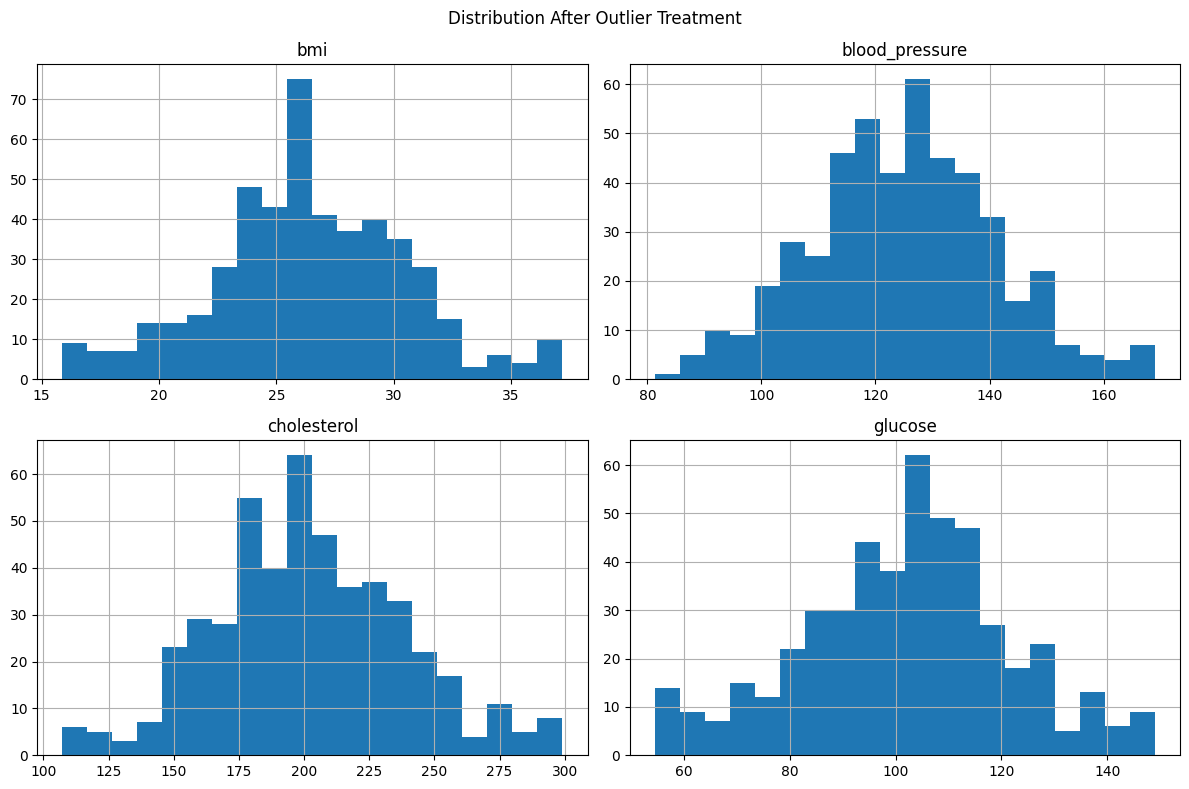

In [50]:
data_capped[["bmi", "blood_pressure", "cholesterol", "glucose"]].hist(
    figsize=(12, 8),
    bins=20
)

plt.suptitle("Distribution After Outlier Treatment")
plt.tight_layout()
plt.show()

بلشت بالانكودنغ

In [51]:
data_encoded = data_capped.copy()

In [52]:
data_encoded = pd.get_dummies(data_encoded,columns=["gender", "region"],
    drop_first=True,dtype=int
)

In [53]:
data_encoded.head()

,patient_id,age,bmi,blood_pressure,cholesterol,glucose,disease_risk,gender_Male,region_North,region_South,region_West
0,1001,56,24.2,125.4000,191.50,102.55,0,0,0,1,0
1,1002,69,26.4,148.7000,203.90,108.10,1,1,0,1,0
2,1003,46,28.6,139.3000,287.90,126.00,1,1,0,0,1
3,1004,32,20.8,169.0125,188.10,96.30,1,1,0,0,1
4,1005,60,26.4,118.9000,201.05,141.00,1,0,1,0,0


In [54]:
data_encoded.dtypes

,0
patient_id,int64
age,int64
bmi,float64
blood_pressure,float64
cholesterol,float64
glucose,float64
disease_risk,int64
gender_Male,int64
region_North,int64
region_South,int64


In [55]:
scale_cols = [
    "age",
    "bmi",
    "blood_pressure",
    "cholesterol",
    "glucose"
]

In [56]:
data_minmax = data_encoded.copy()

In [57]:
scaler = MinMaxScaler()

data_minmax[scale_cols] = scaler.fit_transform(
    data_minmax[scale_cols]
)

In [58]:
data_minmax[scale_cols].describe()

,age,bmi,blood_pressure,cholesterol,glucose
count,480.000000,480.000000,480.000000,480.000000,480.000000
mean,0.519228,0.494215,0.497722,0.496306,0.499015
std,0.292494,0.196007,0.185470,0.191897,0.210823
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.278689,0.375000,0.375000,0.375000,0.375000
50%,0.524590,0.493545,0.502708,0.488861,0.508210
75%,0.770492,0.625000,0.625000,0.625000,0.625000
max,1.000000,1.000000,1.000000,1.000000,1.000000


In [59]:
data_standard = data_encoded.copy()

scaler_standard = StandardScaler()

data_standard[scale_cols] = scaler_standard.fit_transform(
    data_standard[scale_cols]
)

In [60]:
data_standard[scale_cols].describe()

,age,bmi,blood_pressure,cholesterol,glucose
count,4.800000e+02,4.800000e+02,4.800000e+02,4.800000e+02,4.800000e+02
mean,4.440892e-17,3.330669e-17,5.514108e-16,2.294461e-16,3.071617e-16
std,1.001043e+00,1.001043e+00,1.001043e+00,1.001043e+00,1.001043e+00
min,-1.777028e+00,-2.524040e+00,-2.686378e+00,-2.589006e+00,-2.369455e+00
25%,-8.232326e-01,-6.088498e-01,-6.623726e-01,-6.327991e-01,-5.888564e-01
50%,1.835120e-02,-3.421767e-03,2.691237e-02,-3.883518e-02,4.365829e-02
75%,8.599351e-01,6.679440e-01,6.869642e-01,6.713391e-01,5.982090e-01
max,1.645413e+00,2.583135e+00,2.710969e+00,2.627546e+00,2.378807e+00


In [61]:
print(data_encoded.shape)
print("_________________________________")
print(data_encoded.isnull().sum())
print("___________________________________")
print(data_encoded.dtypes)

(480, 11)
_________________________________
patient_id        0
age               0
bmi               0
blood_pressure    0
cholesterol       0
glucose           0
disease_risk      0
gender_Male       0
region_North      0
region_South      0
region_West       0
dtype: int64
___________________________________
patient_id          int64
age                 int64
bmi               float64
blood_pressure    float64
cholesterol       float64
glucose           float64
disease_risk        int64
gender_Male         int64
region_North        int64
region_South        int64
region_West         int64
dtype: object
